## Example usage of a single optimisation + plot results

In [1]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.sqe_state import sqe_optimisation, _make_system_and_observable, _make_driven_sys
from pulse_vqe_entanglement.plotting_state import plot_sqe_optimisation

### Check gradient function

In [2]:
config = SimulationConfig(
    zeeman_splittings=np.array([0.0, 8.0]),
    initial_state=np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128),
    theta_target=0.1 * np.pi,
    n_time_steps=20,
    T=200.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-3,
    feromagnetic=False,
    gtol=1e-15, 
)

sys, observable = _make_system_and_observable(config)
driven_sys = _make_driven_sys(config, sys)

x = np.random.uniform(-1.0, 1.0, size=config.n_time_steps)

driven_sys.gradient(x, observable)

Tracing control amplitude graph.


(np.float64(0.2419119609059489),
 array([ 0.11431308,  0.13050764,  0.11403049,  0.0655649 ,  0.01008726,
        -0.02126528, -0.03144177, -0.00313   ,  0.04641017,  0.09712751,
         0.12976384,  0.1257476 ,  0.08822999,  0.03106546, -0.03055643,
        -0.07976155, -0.10331551, -0.09952375, -0.05982917, -0.00304942]))

### Full run

Tracing control amplitude graph.
Infidelity: I=2.221e-13, nit=4, success=True, grad_norm=1.046e-06
2.2206056956048442e-13
0.000980315711347222
1.0464179776819053e-06


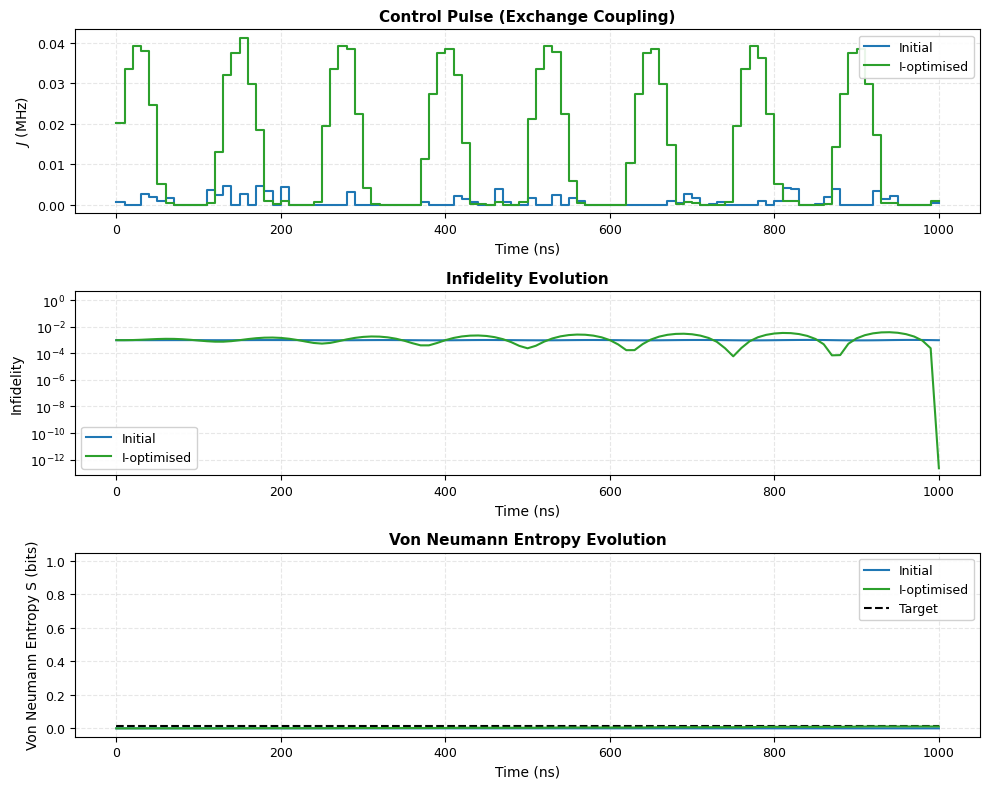

In [5]:
config = SimulationConfig(
    zeeman_splittings=np.array([0.0, 8.0]),
    initial_state=np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128),
    theta_target=0.01 * np.pi,
    n_time_steps=100,
    T=1000.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-3,
    J_init_mean=-1.0,
    feromagnetic=False,
    gtol=1e-15, 
)

results = sqe_optimisation(config)

print(results.val_final[-1])
print(results.val0[-1])
print(results.gradient_norm)

plot_sqe_optimisation(results, figsize=(10, 8))

## Experimenting with entanglement entropy

In [7]:
import numpy as np
import tensorflow as tf
import sys
from pathlib import Path
from scipy.optimize import minimize
from qugradlab.systems.semiconducting.esr import SpinChain

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig, SQEResults
from pulse_vqe_entanglement.sqe_state import *
from pulse_vqe_entanglement.plotting_state import plot_sqe_optimisation
from pulse_vqe_entanglement.entanglement_measures import von_neumann_entropy_traj

zeeman_splittings = np.array([0.0, 8.0])
max_drive_strength = 0.0
J_max = 10.0
J_min = 0.0
feromagnetic = False
theta_target = 0.1 * np.pi
initial_state = np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128)
n_time_steps = 20
T = 200.0
J_init_scale = 1e-2
gtol = 1e-15

In [8]:
config = SimulationConfig(
    zeeman_splittings=zeeman_splittings,
    initial_state=initial_state,
    theta_target=theta_target,
    n_time_steps=n_time_steps,
    T=T,
    max_drive_strength=max_drive_strength,
    J_max=J_max,
    J_min=J_min,
    J_init_scale=J_init_scale,
    feromagnetic=feromagnetic,
    gtol=gtol,
)

sys = SpinChain(
    spins=2,
    zeeman_splittings=zeeman_splittings,
    max_drive_strength=max_drive_strength,
    J_max=J_max,
    J_min=J_min,
    feromagnetic=feromagnetic,
    use_graph=True,
)

target_state = single_qubit_excitation(theta_target) @ initial_state
observable = np.eye(4, dtype=np.complex128) - np.outer(target_state, target_state.conj())

x0 = J_init_scale * np.random.uniform(-1.0, 1.0, size=(n_time_steps * 1))

def pulse_function(x):
    if max_drive_strength == 0.0:
        drive_amps = convert_dtype(np.zeros((n_time_steps, 2)))
        J_amps = tf.reshape(convert_dtype(x), (n_time_steps, 1))
    else:
        drive_amps = tf.reshape(convert_dtype(x[:n_time_steps * 2]), (n_time_steps, 2)) + 1j * tf.reshape(convert_dtype(x[n_time_steps * 2:n_time_steps * 4]), (n_time_steps, 2))
        J_amps = tf.reshape(convert_dtype(x[n_time_steps * 4:]), (n_time_steps, 1))

    init = convert_dtype(initial_state)
    drive_freqs = convert_dtype(zeeman_splittings)

    dt = T / n_time_steps

    return drive_amps, drive_freqs, J_amps, init, dt

driven_sys = sys.pulse_form(pulse_function)


Tracing control amplitude graph.


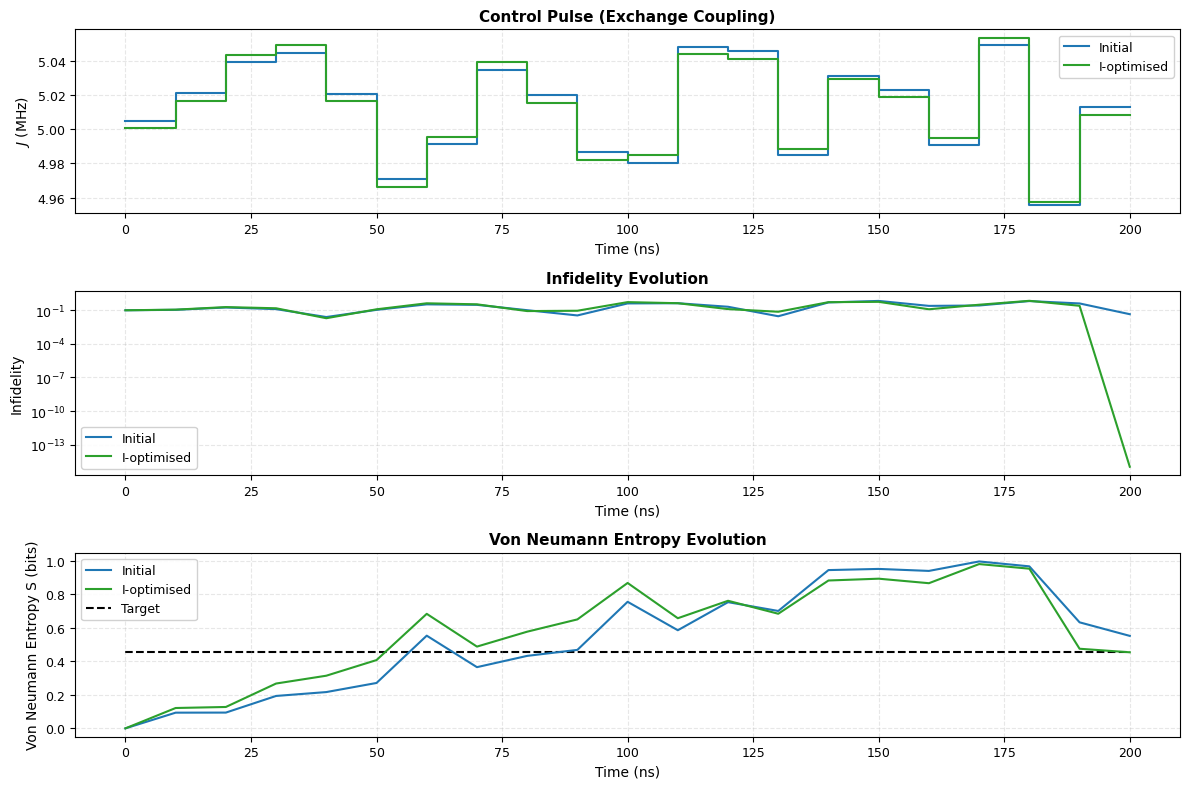

In [9]:
result_wo_entropy = minimize(
    driven_sys.gradient,
    x0=x0,
    args=(observable,),
    jac=True,
    bounds=[(-1.0, 1.0)] * len(x0),
    method="L-BFGS-B",
    options={"maxiter": 200, "gtol": gtol},
)

xf_wo_entropy = result_wo_entropy.x
val0 = np.real(driven_sys.evolved_expectation_value_all(x0, observable))
val_final_wo_entropy = np.real(driven_sys.evolved_expectation_value_all(xf_wo_entropy, observable))
initial_traj = driven_sys.propagate_all(x0)
final_traj_wo_entropy = driven_sys.propagate_all(xf_wo_entropy)
gradient_norm_wo_entropy = float(np.linalg.norm(result_wo_entropy.jac))
n_iterations_wo_entropy = result_wo_entropy.nit
optimization_success_wo_entropy = result_wo_entropy.success

res_wo_entropy = SQEResults(
    config=config,
    x0=x0,
    x_final=xf_wo_entropy,
    val0=val0,
    val_final=val_final_wo_entropy,
    initial_traj=initial_traj,
    final_traj=final_traj_wo_entropy,
    gradient_norm=gradient_norm_wo_entropy,
    n_iterations=n_iterations_wo_entropy,
    optimization_success=optimization_success_wo_entropy,
)

plot_sqe_optimisation(res_wo_entropy)

Initial expectation value: 0.04280097368811088
Initial entropy penalty: 0.3442903871932658
Initial adiabaticity penalty: 0.0005213752678769292
  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.01857707067697315
        x: [-5.077e-03  1.411e-03 ...  4.772e-03  1.929e-03]
      nit: 25
      jac: [ 5.509e-01  2.290e+00 ... -3.644e-01 -4.750e-01]
     nfev: 297
     njev: 297
 hess_inv: <20x20 LbfgsInvHessProduct with dtype=float64>


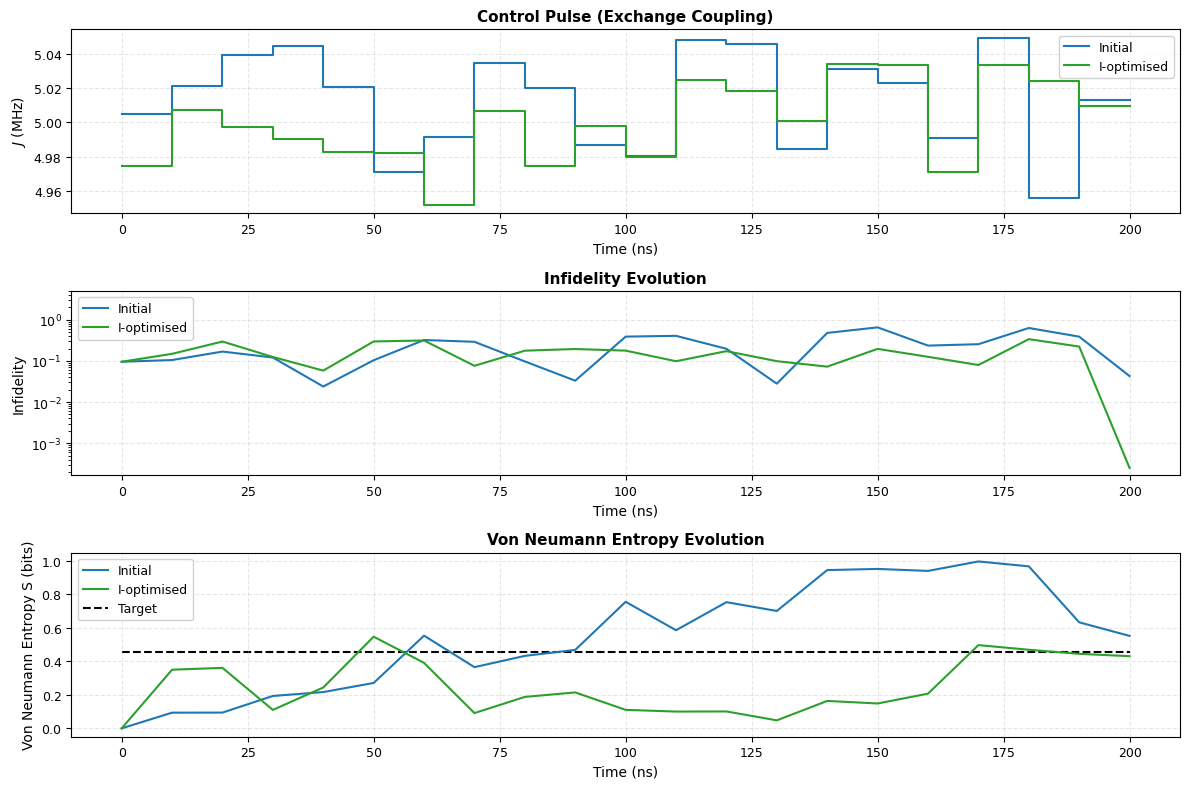

In [10]:
### Method 1: total entropy
'''
def entropy_penalty(x, lam=1e-2):
    traj = np.asarray(driven_sys.propagate_all(x))  # (4, n_t)
    S = np.array(von_neumann_entropy_traj(traj), dtype=float)
    return lam * S.mean()
'''

### Method 2: only penalise entropy above a certain threshold (cleaner landscape)
def entropy_penalty(x, S_max=0.05):
    traj = np.asarray(driven_sys.propagate_all(x))  # (4, n_t)
    S = np.asarray(von_neumann_entropy_traj(traj), float)
    viol = np.maximum(0.0, S - S_max)
    return np.mean(viol**2)


### Method 3: penalise the maximum only
'''
def entropy_penalty(x):
    traj = np.asarray(driven_sys.propagate_all(x))  # (4, n_t)
    S = np.array(von_neumann_entropy_traj(traj), dtype=float)
    S_max = S.max()
    return S_max
'''

def entropy_grad_fd(x, eps=1e-6):
    grad = np.zeros_like(x, dtype=float)
    f0 = entropy_penalty(x)

    for i in range(len(x)):
        x_eps = np.array(x, dtype=float)
        x_eps[i] += eps
        f_eps = entropy_penalty(x_eps)
        grad[i] = (f_eps - f0) / eps

    return grad

def loss_and_grad_entropy(x, lam, observable, eps=1e-6):
    val_T, grad_T = driven_sys.gradient(x, observable)

    pen = lam * entropy_penalty(x)
    grad_pen = lam * entropy_grad_fd(x, eps)

    return float(np.real(val_T) + pen), (np.asarray(grad_T, float) + grad_pen)

### Method 4: penalise adiabaticity (integral of dS/dt)^2

def adiabaticity_penalty(x):
    '''
    traj = np.asarray(driven_sys.propagate_all(x))  # (4, n_t)
    S = np.asarray(von_neumann_entropy_traj(traj), float)
    dS_dt = np.diff(S) / (T / n_time_steps)
    adiabaticity = np.mean(dS_dt**2)
    return lam * adiabaticity
    '''
    I = np.real(driven_sys.evolved_expectation_value_all(x, observable))
    I = np.asarray(I, float)
    dI_dt = np.diff(I) / (T / n_time_steps)
    adiabaticity = np.mean(dI_dt**2)
    return adiabaticity

def adiabaticity_grad_fd(x, eps=1e-6):
    grad = np.zeros_like(x, dtype=float)
    f0 = adiabaticity_penalty(x)

    for i in range(len(x)):
        x_eps = np.array(x, dtype=float)
        x_eps[i] += eps
        f_eps = adiabaticity_penalty(x_eps)
        grad[i] = (f_eps - f0) / eps

    return grad

def loss_and_grad_adiabaticity(x, observable, lam=1e-2, eps=1e-6):
    val_T, grad_T = driven_sys.gradient(x, observable)

    pen = lam * adiabaticity_penalty(x)
    grad_pen = lam * adiabaticity_grad_fd(x, eps)

    return float(np.real(val_T) + pen), (np.asarray(grad_T, float) + grad_pen)

# Combine entropy and smoothness penalties

def loss_and_grad_combined(x, observable, lam_entropy=1e-2, lam_adiabaticity=1e-2, eps=1e-2):
    val_T, grad_T = driven_sys.gradient(x, observable)

    pen_entropy = lam_entropy * entropy_penalty(x)
    grad_pen_entropy = lam_entropy * entropy_grad_fd(x, eps)

    pen_adiabaticity = lam_adiabaticity * adiabaticity_penalty(x)
    grad_pen_adiabaticity = lam_adiabaticity * adiabaticity_grad_fd(x, eps)

    total_penalty = pen_entropy + pen_adiabaticity
    total_grad_penalty = grad_pen_entropy + grad_pen_adiabaticity

    return float(np.real(val_T) + total_penalty), (np.asarray(grad_T, float) + total_grad_penalty)

# Check values to match scale
print("Initial expectation value:", np.real(driven_sys.evolved_expectation_value_all(x0, observable))[-1])
print("Initial entropy penalty:", entropy_penalty(x0))
print("Initial adiabaticity penalty:", adiabaticity_penalty(x0))

# Optimisation

result_w_entropy = minimize(
    loss_and_grad_combined,
    #loss_and_grad_entropy,
    x0=x0,
    args=(observable, 1e-2, 1e2),
    jac=True,
    bounds=[(-1.0, 1.0)] * len(x0),
    method="L-BFGS-B",
    options={"maxiter": 200, "gtol": gtol},
)

xf_w_entropy = result_w_entropy.x
val0_w_entropy = np.real(driven_sys.evolved_expectation_value_all(x0, observable))
val_final_w_entropy = np.real(driven_sys.evolved_expectation_value_all(xf_w_entropy, observable))
initial_traj_w_entropy = driven_sys.propagate_all(x0)
final_traj_w_entropy = driven_sys.propagate_all(xf_w_entropy)
gradient_norm_w_entropy = float(np.linalg.norm(result_w_entropy.jac))
n_iterations_w_entropy = result_w_entropy.nit
optimization_success_w_entropy = result_w_entropy.success
res_w_entropy = SQEResults(
    config=config,
    x0=x0,
    x_final=xf_w_entropy,
    val0=val0_w_entropy,
    val_final=val_final_w_entropy,
    initial_traj=initial_traj_w_entropy,
    final_traj=final_traj_w_entropy,
    gradient_norm=gradient_norm_w_entropy,
    n_iterations=n_iterations_w_entropy,
    optimization_success=optimization_success_w_entropy,
)
print(result_w_entropy)
plot_sqe_optimisation(res_w_entropy)

## Lagrange multiplier to fix fidelity

In [ ]:
import numpy as np
import tensorflow as tf
import sys
from pathlib import Path
from scipy.optimize import minimize
from qugradlab.systems.semiconducting.esr import SpinChain

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig, SQEResults
from pulse_vqe_entanglement.sqe_optimisation import *
from pulse_vqe_entanglement.plotting import plot_sqe_optimisation
from pulse_vqe_entanglement.entanglement_measures import von_neumann_entropy_traj

zeeman_splittings = np.array([0.0, 8.0])
max_drive_strength = 0.0
J_max = 10.0
J_min = 0.0
feromagnetic = False
theta_target = 0.1 * np.pi
initial_state = np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128)
n_time_steps = 20
T = 200.0
J_init_scale = 1e-2
gtol = 1e-15

In [ ]:
config = SimulationConfig(
    zeeman_splittings=zeeman_splittings,
    initial_state=initial_state,
    theta_target=theta_target,
    n_time_steps=n_time_steps,
    T=T,
    max_drive_strength=max_drive_strength,
    J_max=J_max,
    J_min=J_min,
    J_init_scale=J_init_scale,
    feromagnetic=feromagnetic,
    gtol=gtol,
)

sys = SpinChain(
    spins=2,
    zeeman_splittings=zeeman_splittings,
    max_drive_strength=max_drive_strength,
    J_max=J_max,
    J_min=J_min,
    feromagnetic=feromagnetic,
    use_graph=True,
)

target_state = single_qubit_excitation(theta_target) @ initial_state
observable = np.eye(4, dtype=np.complex128) - np.outer(target_state, target_state.conj())

x0 = J_init_scale * np.random.uniform(-1.0, 1.0, size=(n_time_steps * 1))
x0 = np.append(x0, 1.0e-1) # initial lagrange multiplier


def pulse_function(x):
    if max_drive_strength == 0.0:
        drive_amps = convert_dtype(np.zeros((n_time_steps, 2)))
        J_amps = tf.reshape(convert_dtype(x), (n_time_steps, 1))
    else: 
        drive_amps = tf.reshape(convert_dtype(x[:n_time_steps * 2]), (n_time_steps, 2)) + 1j * tf.reshape(convert_dtype(x[n_time_steps * 2:n_time_steps * 4]), (n_time_steps, 2))
        J_amps = tf.reshape(convert_dtype(x[n_time_steps * 4:]), (n_time_steps, 1))

    init = convert_dtype(initial_state)
    drive_freqs = convert_dtype(zeeman_splittings)

    dt = T / n_time_steps

    return drive_amps, drive_freqs, J_amps, init, dt

driven_sys = sys.pulse_form(pulse_function)

In [ ]:
def cost_entropy(x, S_max=0.05):
    traj = np.asarray(driven_sys.propagate_all(x))  # (4, n_t)
    S = np.asarray(von_neumann_entropy_traj(traj), float)
    viol = np.maximum(0.0, S - S_max)
    return np.mean(viol**2)

def entropy_grad_fd(x, eps=1e-6):
    grad = np.zeros_like(x, dtype=float)
    f0 = cost_entropy(x)

    for i in range(len(x)-1):
        x_eps = np.array(x, dtype=float)
        x_eps[i] += eps
        f_eps = cost_entropy(x_eps)
        grad[i] = (f_eps - f0) / eps

    return grad

def cost_adiabaticity(x):
    I = np.real(driven_sys.evolved_expectation_value_all(x, observable))
    I = np.asarray(I, float)
    dI_dt = np.diff(I) / (T / n_time_steps)
    adiabaticity = np.mean(dI_dt**2)
    return adiabaticity

def adiabaticity_grad_fd(x, eps=1e-6):
    grad = np.zeros_like(x, dtype=float)
    f0 = cost_adiabaticity(x)

    for i in range(len(x)-1):
        x_eps = np.array(x, dtype=float)
        x_eps[i] += eps
        f_eps = cost_adiabaticity(x_eps)
        grad[i] = (f_eps - f0) / eps

    return grad

def cost_and_grad_with_multiplier(x, observable, lam_entropy=1e-2, lam_adiabaticity=1e-2, eps=1e-2):
    infidelity, infidelity_grad = driven_sys.gradient(x, observable)

    pen_entropy = cost_entropy(x)
    grad_pen_entropy = entropy_grad_fd(x, eps)

    pen_adiabaticity = cost_adiabaticity(x)
    grad_pen_adiabaticity = adiabaticity_grad_fd(x, eps)

    total_penalty = lam_entropy * pen_entropy + lam_adiabaticity * pen_adiabaticity + x[-1] * infidelity[-1]
    total_grad_penalty = lam_entropy * grad_pen_entropy + lam_adiabaticity * grad_pen_adiabaticity + x[-1] * infidelity_grad
    total_grad_penalty = np.append(total_grad_penalty, infidelity[-1])

    return total_penalty, total_grad_penalty

Tracing control amplitude graph.
Initial expectation value: 0.4667712698724697
Initial entropy penalty: 0.053075788421684894
Initial adiabaticity penalty: 0.0004825803222580489
  message: ABNORMAL: 
  success: False
   status: 2
      fun: 0.1117853523455495
        x: [ 4.931e-02 -3.766e-02 ... -1.490e-02  1.000e-01]
      nit: 54
      jac: [ 2.308e+00  2.215e-01 ... -9.027e-01  0.000e+00]
     nfev: 467
     njev: 467
 hess_inv: <21x21 LbfgsInvHessProduct with dtype=float64>


ValueError: x and y must have same first dimension, but have shapes (21,) and (22,)

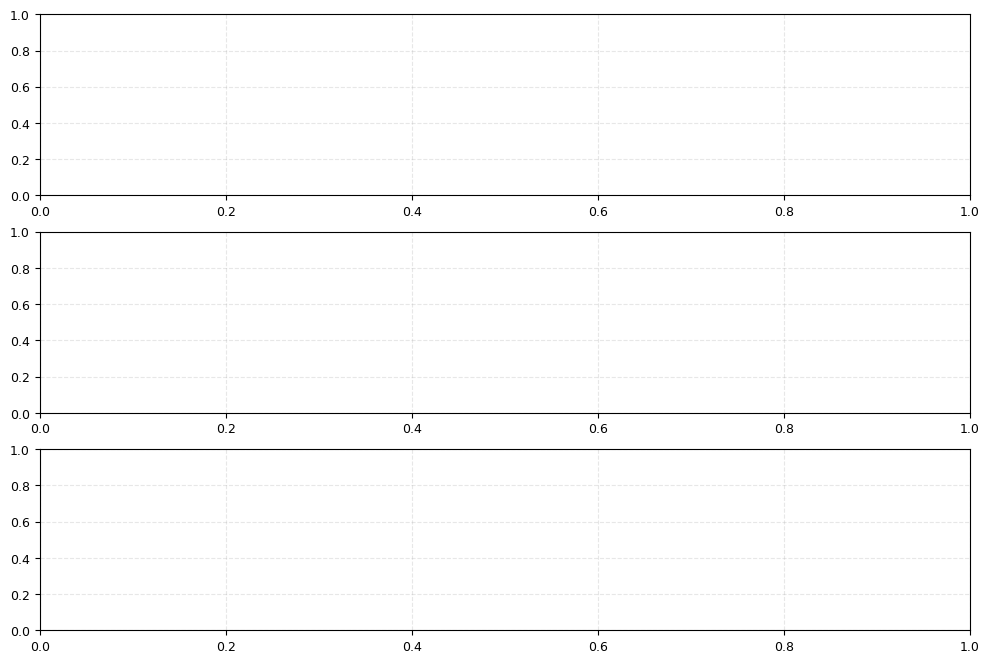

In [18]:
# Check valus to match scale
print("Initial expectation value:", np.real(driven_sys.evolved_expectation_value_all(x0, observable))[-1])
print("Initial entropy penalty:", entropy_penalty(x0))
print("Initial adiabaticity penalty:", adiabaticity_penalty(x0))

# Optimisation

result_w_entropy = minimize(
    loss_and_grad_combined,
    #loss_and_grad_entropy,
    x0=x0,
    args=(observable, 1e-2, 1e2),   
    jac=True,
    bounds=[(-1.0, 1.0)] * len(x0),
    method="L-BFGS-B",
    options={"maxiter": 200, "gtol": gtol},
)

xf_w_entropy = result_w_entropy.x
val0_w_entropy = np.real(driven_sys.evolved_expectation_value_all(x0, observable))
val_final_w_entropy = np.real(driven_sys.evolved_expectation_value_all(xf_w_entropy, observable))
initial_traj_w_entropy = driven_sys.propagate_all(x0)
final_traj_w_entropy = driven_sys.propagate_all(xf_w_entropy)
gradient_norm_w_entropy = float(np.linalg.norm(result_w_entropy.jac))
n_iterations_w_entropy = result_w_entropy.nit
optimization_success_w_entropy = result_w_entropy.success
res_w_entropy = SQEResults(
    config=config,
    x0=x0,
    x_final=xf_w_entropy,
    val0=val0_w_entropy,
    val_final=val_final_w_entropy,
    initial_traj=initial_traj_w_entropy,
    final_traj=final_traj_w_entropy,
    gradient_norm=gradient_norm_w_entropy,
    n_iterations=n_iterations_w_entropy,
    optimization_success=optimization_success_w_entropy,
)
print(result_w_entropy)
plot_sqe_optimisation(res_w_entropy)